# Evaluate Feature Random Forest with Different Channel Sets

In [5]:
# Setup imports and load optimal parameters for features_rf
import json
from pathlib import Path
from classification.training_utils import evaluate_single_model
from data.data_configs import SUBJECTS, DEFAULT_EEG_CHANNELS

opt_file = Path.cwd() / 'results' / 'optimal_parameters_normal_latest.json'
with open(opt_file, 'r') as f:
    optimal = json.load(f)
params = optimal.get('features_rf', {}).get('params', {})

# Channel sets to evaluate (None uses default/all feature set)
channel_sets = [
    ['Oz', 'O1', 'O2'], # visual cortex channels
    ['P3', 'P4', 'Pz'], # parietal channels
    ['T7', 'T8'], # temporal channels
    ['F3', 'F4', 'FC1', 'FC2', 'Fz'], # frontal channels
    ['C3', 'C4', 'CP1', 'CP2', 'Cz'] # central channels
]

out_file = Path.cwd() / 'results' / 'feature_rf_channel_eval.json'
results = {}
if out_file.exists():
    with open(out_file, 'r') as f:
        results = json.load(f)


In [6]:
# Evaluate and save per channel set
import numpy as np
def make_jsonable(o):
    # Recursively convert objects to JSON-serializable Python types
    if isinstance(o, dict):
        return {k: make_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [make_jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return make_jsonable(o.tolist())
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o

In [33]:

for cs in channel_sets:
    label = ('_'.join(cs) if isinstance(cs, (list, tuple)) else str(cs))
    if label in results:
        continue
    res = evaluate_single_model('features_rf', SUBJECTS, params, selected_channels=cs, split_strategy='normal')
    filtered = {
        'balanced_acc': res.get('balanced_acc'),
        'auroc': res.get('auroc'),
        'confusion_matrix': res.get('confusion_matrix'),
    }
    results[label] = make_jsonable(filtered)
    with open(out_file, 'w') as f:
        json.dump(make_jsonable(results), f, indent=2)
    print(f"Finished: {label}")


Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P01)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P07)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P09)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P10)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P16)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P17)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P20)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P21)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P27)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P28)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P30)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P34)
Filtered to 46 features for channels ['P3', 'P4', 'Pz'] (subject P38)
  Data shape: (33008, 45), dtype: float32
  Memory usage: 5.7 MB

RANDOM TRAIN/VAL/TEST SP

In [34]:
# Print a concise summary of results
for k, v in results.items():
    if isinstance(v, dict) and 'balanced_acc' in v:
        print(f"{k}: balanced_acc={v['balanced_acc']}")
    elif isinstance(v, dict) and 'score' in v:
        print(f"{k}: score={v['score']}")
    elif isinstance(v, dict) and 'error' in v:
        print(f"{k}: ERROR - {v['error']}")
    else:
        print(f"{k}: result keys={list(v.keys()) if isinstance(v, dict) else type(v)}")

Oz_O1_O2: balanced_acc=0.664981328149143
P3_P4_Pz_PO3_PO4: balanced_acc=0.664873705933392
T7_T8_CP5_CP6: balanced_acc=0.6589875414517318
F3_F4_FC1_FC2_Fz: balanced_acc=0.6712612097962773
C3_C4_CP1_CP2_Cz: balanced_acc=0.6604334305988067
P3_P4_Pz: balanced_acc=0.657148399428293
T7_T8: balanced_acc=0.6464491354565336


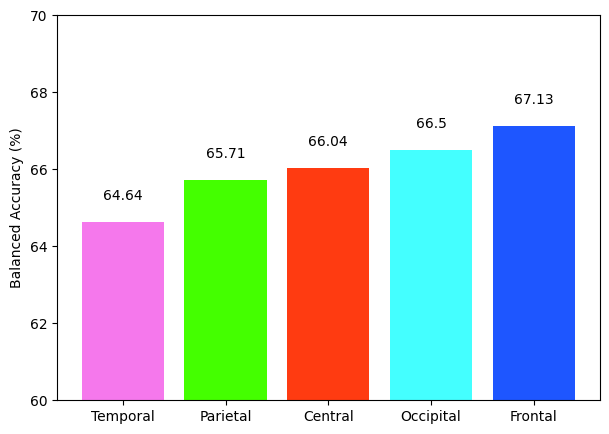

In [45]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

# Load results
out_file = Path.cwd() / 'results' / 'feature_rf_channel_eval.json'
with open(out_file, 'r') as f:
    saved = json.load(f)

# Define categories and mapping to saved labels (order: Frontal, Central, Temporal, Parietal, Occipital)
categories = ['Frontal', 'Central', 'Temporal', 'Parietal', 'Occipital']
label_map = {
    'Frontal': 'F3_F4_FC1_FC2_Fz',
    'Central': 'C3_C4_CP1_CP2_Cz',
    'Temporal': 'T7_T8',
    'Parietal': 'P3_P4_Pz',
    'Occipital': 'Oz_O1_O2',
}

# Extract balanced accuracy (percent) per category
values = []
for cat in categories:
    label = label_map[cat]
    entry = saved.get(label, {})
    bal = entry.get('balanced_acc')
    values.append(round(100.0 * bal, 2) if isinstance(bal, (int, float)) and bal is not None else 0.0)

# Color palette (Blue, Red-Orange, Magenta, Bright Green, Cyan)
colors = [
    '#1e56ff',  # Frontal (Blue)
    '#ff3b11',  # Central (Red-Orange)
    '#f578ec',  # Temporal (Magenta/Pink)
    '#44ff00',  # Parietal (Green)
    '#44ffff',  # Occipital (Cyan)
]

# Sort by value (descending), keeping category-color alignment
sorted_triplets = sorted(zip(categories, values, colors), key=lambda x: x[1], reverse=False)
categories, values, colors = map(list, zip(*sorted_triplets))

plt.figure(figsize=(7, 5))
bars = plt.bar(categories, values, color=colors, linewidth=0.5)
plt.ylabel('Balanced Accuracy (%)')

# Labels above bars
for bar, val in zip(bars, values):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f"{val}", ha='center', va='bottom', fontsize=10)

plt.ylim(60,70)
plt.show()

## Check if Number of planes has an influence

In [7]:
evaluate_single_model("features_rf", SUBJECTS, params, stimulus_summary=True)

Filtered to 286 features for channels ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2'] (subject P01)
Filtered to 286 features for channels ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2'] (subject P07)
Filtered to 286 features for channels ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2'] (subject P09)
Filtered to 286 features for channels ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2'] (subject P10)
Filtered to 286 features for channels ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2'] (subject P16)
Filtered to 286 features for channels ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2'] 

ValueError: Found input variables with inconsistent numbers of samples: [33008, 33008, 2452]